In [1]:
# Install if required
# !pip install tensorflow pandas numpy matplotlib seaborn scikit-learn

import os
import random
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.layers import (
    TextVectorization,
    Embedding,
    Bidirectional,
    LSTM,
    Dropout,
    Dense
)

from tensorflow.keras.models import Sequential

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# Download dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

zip_path = "sms_spam_collection.zip"

urllib.request.urlretrieve(url, zip_path)

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("sms_dataset")

# Load dataset
file_path = "sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep='\t',
    header=None,
    names=['label', 'message'],
    encoding='latin-1'
)

# Display first five rows
print("First five records:")
display(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Class distribution
print("\nClass Distribution:")
print(df['label'].value_counts())

# Class percentages
print("\nClass Percentage:")
print(df['label'].value_counts(normalize=True) * 100)

First five records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Dataset Shape: (5572, 2)

Missing Values:
label      0
message    0
dtype: int64

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Class Percentage:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


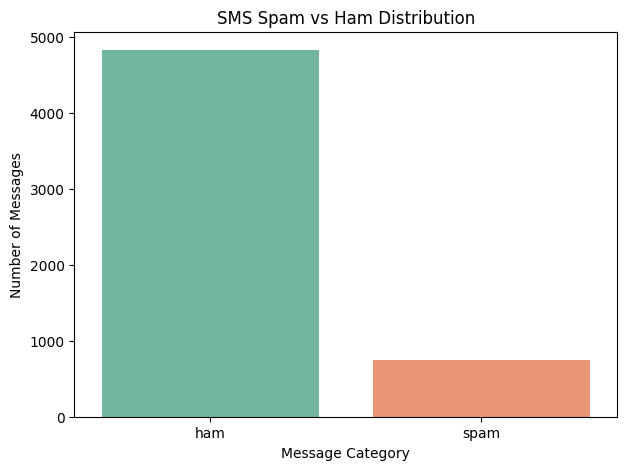

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label',
    hue='label',
    palette='Set2',
    legend=False
)

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

Minimum length: 1
Maximum length: 171
Mean length: 15.597451543431443


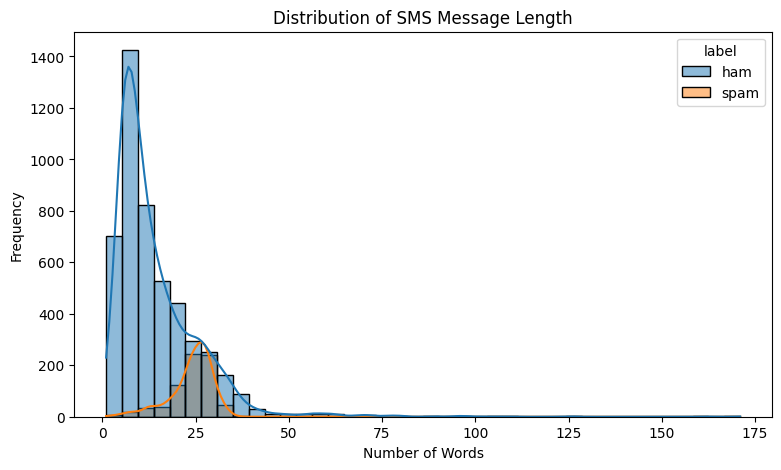

In [4]:
df['message_length'] = df['message'].apply(
    lambda x: len(x.split())
)

print("Minimum length:", df['message_length'].min())
print("Maximum length:", df['message_length'].max())
print("Mean length:", df['message_length'].mean())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title("Distribution of SMS Message Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [5]:
print("Example HAM message:")
print(df[df['label'] == 'ham']['message'].iloc[0])

print("\nExample SPAM message:")
print(df[df['label'] == 'spam']['message'].iloc[0])

Example HAM message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Example SPAM message:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [6]:
# Convert labels
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

X = df['message'].astype(str).values
y = df['label'].values

print("Total messages:", len(X))
print("Total labels:", len(y))

Total messages: 5572
Total labels: 5572


In [7]:
# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Second split: 10% validation, 10% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 4457
Validation samples: 557
Testing samples: 558


In [8]:
VOCAB_SIZE = 10000
MAXLEN = 50

print("Vocabulary size:", VOCAB_SIZE)
print("Maximum sequence length:", MAXLEN)

Vocabulary size: 10000
Maximum sequence length: 50


In [9]:
vectorizer = TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAXLEN
)

# Adapt using training text only
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(32)
)

# Convert text into integer sequences
X_train_vec = vectorizer(X_train)
X_val_vec = vectorizer(X_val)
X_test_vec = vectorizer(X_test)

print("Training shape:", X_train_vec.shape)
print("Validation shape:", X_val_vec.shape)
print("Testing shape:", X_test_vec.shape)

# Display example
print("\nOriginal message:")
print(X_train[0])

print("\nInteger encoded message:")
print(X_train_vec[0].numpy())

Training shape: (4457, 50)
Validation shape: (557, 50)
Testing shape: (558, 50)

Original message:
He will, you guys close?

Integer encoded message:
[ 75  33   4 311 666   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [13]:
EMBEDDING_DIM = 64
LSTM_UNITS = 64

model = Sequential([

    # Explicitly define input shape
    tf.keras.Input(shape=(MAXLEN,), dtype=tf.int64),

    # Embedding layer
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    # Bidirectional LSTM
    Bidirectional(
        LSTM(
            LSTM_UNITS,
            use_cudnn=False
        )
    ),

    # Dropout
    Dropout(0.3),

    # Output layer
    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,177 (2.69 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
EPOCHS = 5
BATCH_SIZE = 32

history = model.fit(
    X_train_vec,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_vec, y_val),
    verbose=1
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 207ms/step - accuracy: 0.9345 - loss: 0.2236 - val_accuracy: 0.9820 - val_loss: 0.0790
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.9933 - loss: 0.0326 - val_accuracy: 0.9820 - val_loss: 0.0612
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.9969 - loss: 0.0130 - val_accuracy: 0.9838 - val_loss: 0.0591
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 215ms/step - accuracy: 0.9984 - loss: 0.0066 - val_accuracy: 0.9838 - val_loss: 0.0602
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.9996 - loss: 0.0025 - val_accuracy: 0.9820 - val_loss: 0.1002


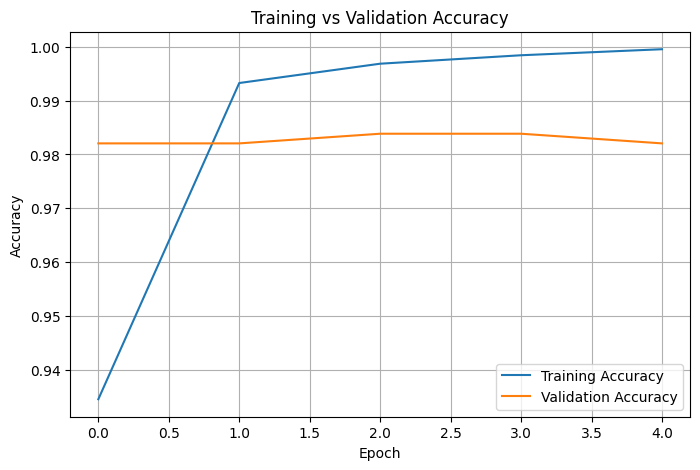

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

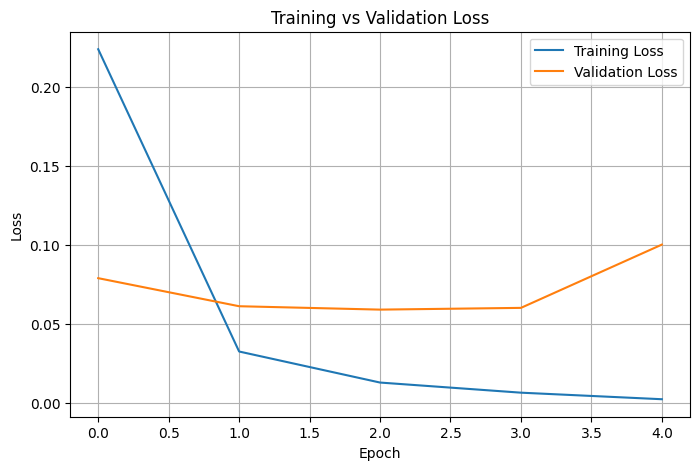

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(
    X_test_vec,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9875 - loss: 0.0769

Test Loss: 0.07694999873638153
Test Accuracy: 98.74551892280579 %


In [18]:
y_prob = model.predict(X_test_vec)

y_pred = (y_prob >= 0.5).astype(int).flatten()

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step


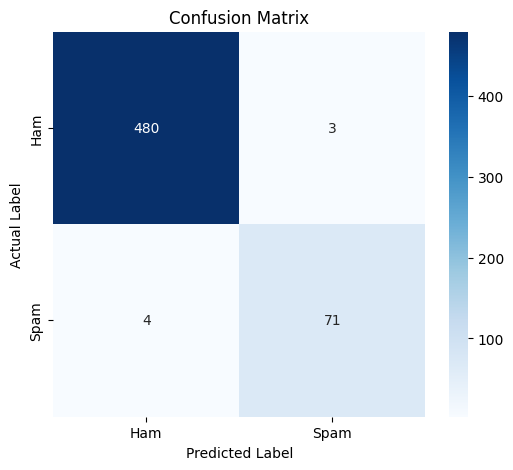

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [20]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Ham', 'Spam'],
        digits=4
    )
)

Classification Report:

              precision    recall  f1-score   support

         Ham     0.9917    0.9938    0.9928       483
        Spam     0.9595    0.9467    0.9530        75

    accuracy                         0.9875       558
   macro avg     0.9756    0.9702    0.9729       558
weighted avg     0.9874    0.9875    0.9874       558



In [21]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Evaluation Metrics")
print("-------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Evaluation Metrics
-------------------------
Accuracy  : 0.9875
Precision : 0.9595
Recall    : 0.9467
F1 Score  : 0.9530


In [22]:
def predict(text):

    # Convert raw text to integer sequence
    sequence = vectorizer(
        tf.constant([text])
    )

    # Predict probability
    probability = model.predict(
        sequence,
        verbose=0
    )[0][0]

    # Determine class
    if probability >= 0.5:
        label = "SPAM"
    else:
        label = "HAM"

    return label, float(probability)

In [23]:
new_messages = [
    "Congratulations! You have won a free prize. Call now!",

    "Hey, are we meeting for lunch today?",

    "URGENT! Claim your free cash reward now!",

    "Can you send me the notes from yesterday's class?",

    "You have been selected for a free vacation. Click here!"
]

print("NEW SMS PREDICTIONS")
print("=" * 60)

for message in new_messages:

    label, probability = predict(message)

    print("\nMessage:", message)
    print("Prediction:", label)
    print("Probability:", round(probability, 4))

NEW SMS PREDICTIONS

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Probability: 0.999

Message: Hey, are we meeting for lunch today?
Prediction: HAM
Probability: 0.0

Message: URGENT! Claim your free cash reward now!
Prediction: SPAM
Probability: 0.9977

Message: Can you send me the notes from yesterday's class?
Prediction: HAM
Probability: 0.0004

Message: You have been selected for a free vacation. Click here!
Prediction: SPAM
Probability: 0.9193


In [24]:
# Save model
model.save("sms_spam_detection_model.keras")

# Save vectorizer vocabulary
vocabulary = vectorizer.get_vocabulary()

with open("sms_vocabulary.txt", "w", encoding="utf-8") as f:
    for word in vocabulary:
        f.write(word + "\n")

print("Model and vocabulary saved successfully!")

Model and vocabulary saved successfully!
